# Predicting Whether a User Will Love a New Recipe: Item Cold-Start on Food.com

CSE 258 Assignment 2。輸入 `(user, 新食譜)`，輸出 **P(rating == 5)**。新食譜在模型可用的資料中沒有任何評論，
所以只能用 user 的歷史評分和食譜內容。

超參數在開發用 notebook（`2_baselines` → `3_similarity` → `4_lr`）的 validation 上選定，存在
`results/params.json`；本 notebook 只讀取，不再調整。**test 只在本 notebook 評估一次。**

| 節 | 報告部分 |
|---|---|
| 1 | 資料與探索（細節見 `1_data_overview.ipynb`） |
| 2 | 預測任務、評估方式與特徵 |
| 3 | 模型 |
| 4 | 結果（validation 與 test） |
| 5 | 相關文獻 |
| 6 | 結論 |

In [15]:
%load_ext autoreload
%autoreload 2

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import *
from features import (RecipeSets, build_features, group_columns, load_interactions, load_recipes,
                      make_snapshot, user_prior, weighted_average, year_snapshot)
from models import (VARIANTS, baseline_constant, fit_lr, lr_coefficients, predict, training_set,
                    tune_beta, tune_weighted_average)
from evaluation import auc, compare, evaluate, mean_ci, pretty
from ranking import ranking_metrics, sample_candidates

warnings.filterwarnings("ignore", category=FutureWarning)  # pandas copy-on-write notices
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4f}".format)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
t0 = time.time()
train, val, test = load_interactions()
recipes = load_recipes()
print(f"loaded in {time.time() - t0:.0f}s: train {len(train):,}, validation {len(val):,}, test {len(test):,}, recipes {len(recipes):,}")

loaded in 10s: train 683,996, validation 22,933, test 22,224, recipes 178,265


In [17]:
P = load_params("BETA", "MAX_DF", "WA", "TRAIN_MODE", "C", "CLASS_WEIGHT", "LAM_USER")
BETA, MAX_DF, WA, TRAIN_MODE, C_BEST, CW, LAM_USER = (P[k] for k in ("BETA", "MAX_DF", "WA", "TRAIN_MODE", "C", "CLASS_WEIGHT", "LAM_USER"))
MODES = [TRAIN_MODE]
print({k: v for k, v in P.items() if k != "WA"}, TRAIN_MODES[TRAIN_MODE])
pd.DataFrame(WA).T

{'BETA': 1.0, 'MAX_DF': 0.35, 'TRAIN_MODE': 'pseudo_cold', 'C': 0.1, 'CLASS_WEIGHT': None, 'LAM_USER': 0.03} {'years_val': [2009, 2010, 2011, 2012], 'years_test': [2010, 2011, 2012], 'cold_only': True, 'weighted': False}


,sim,k,alpha,lam
J1,jac_tag,50,5.0000,0.0000
J1-T,jac_tag,50,5.0000,0.0300
J2,jac_ing,50,2.0000,0.0000
J2-T,jac_ing,50,2.0000,0.0300
C1,cos_tag,50,10.0000,0.0000
C1-T,cos_tag,50,10.0000,0.0300
C2,cos_ing,50,5.0000,0.0000
C2-T,cos_ing,50,5.0000,0.0300


## 1. 資料與探索

Food.com 評論與食譜（Majumder et al., 2019）。依時間切分：train 至 2012 年底、validation 為 2013、test 為 2014–2018；
只保留 train 期間至少有 3 筆評分的 user。官方切分不是依時間，user 歷史特徵會看到未來，因此改用 `preprocess.py` 重新切分。

In [18]:
def split_summary(df, name):
    return {"split": name, "rows": len(df), "users": df.u.nunique(), "recipes": df.recipe_id.nunique(),
            "rating==5": df.y_eq5.mean()}

pd.DataFrame([split_summary(train, "train"), split_summary(val[val.cold == 1], "validation (cold)"),
              split_summary(test[test.cold == 1], "test (cold)")]).set_index("split")

,rows,users,recipes,rating==5
split,,,,
train,683996,27327,166824,0.7553
validation (cold),6410,859,4727,0.7760
test (cold),4099,857,3268,0.7960


## 2. 預測任務、評估與特徵

- **Label**：`y = 1[rating == 5]`（約 80% 為正例，accuracy 沒有鑑別力）。
- **評估**：只看 cold 列。AUC（主要）、log loss、Brier，95% CI 以 user 為單位 bootstrap；
  與 B1 的差距用**配對 bootstrap**（同一批樣本）檢定。另以 **Hit@10／NDCG@10** 評估同一個 user 內的排名。
- **防止 leakage**：每組資料是 (history, targets)，特徵只用 history，且 history 全部早於 targets。

| 用途 | history | targets |
|---|---|---|
| LR 訓練 | train 中 Y 年以前 | train 中 Y 年的列（pseudo-cold 模式只取食譜在 Y 年以前沒有評論的列） |
| validation | train | validation |
| test | train + validation | test |

| 特徵群 | 內容 |
|---|---|
| user | `p_u`、評分次數、平均、標準差、距上次評分天數、時間衰減版 `p_u`、近一年 5 分比例 |
| sim | 8 個相似度加權平均減 `p_u`（相對版）、與 5 分／非 5 分食譜的平均與最大 Jaccard、時間與熱量差距 |
| recipe | 時間、步驟、食材數、營養、描述長度、發布年份、食譜年齡 |
| author | 作者其他食譜的 5 分比例與數量、user 對同一作者的 5 分比例、是否為自己的食譜 |

## 3. 模型

| 代號 | 模型 |
|---|---|
| B0 | 常數（history 的 5 分比例） |
| B1 | `p_u`：user 收縮後的 5 分比例 |
| J1／J2／C1／C2 | Jaccard／Cosine 相似度加權平均（tags／ingredients），λ = 0 |
| …-T | 同上加時間衰減 λ > 0 |
| LR | Logistic Regression（標準化 + L2），全部特徵 |
| GBDT | HistGradientBoosting，同樣特徵 |

```
P(u,i) = ( Σ_j w_uij · y_uj + α · p_u ) / ( Σ_j w_uij + α ),   w_uij = Sim(i,j) · exp(−λ · Δyears)
```

latent factor model 與 bias model 的 β_i 需要該食譜有評論，新食譜無法學到，因此不適用。

In [19]:
rsets = RecipeSets(recipes)
snap_val = make_snapshot("validation", train, val, rsets, H=H, max_df=MAX_DF)
cold_val = snap_val.targets.cold.values == 1
y_val = snap_val.targets[f"y_{LABEL}"].values
u_val = snap_val.targets.u.values
print(f"validation snapshot: {snap_val.n:,} rows ({cold_val.sum():,} cold), {len(snap_val.pairs):,} pairs")
prior_val = user_prior(snap_val, LABEL, BETA)

def snapshot_keys(mode, which):
    m = TRAIN_MODES[mode]
    return [(yr, m["cold_only"]) for yr in m[which]]

t0 = time.time()
snaps_lr = {key: year_snapshot(train, key[0], rsets, cold_only=key[1], H=H, max_df=MAX_DF)
            for key in sorted({k for mode in MODES for which in ("years_val", "years_test") for k in snapshot_keys(mode, which)})}
for s in snaps_lr.values():
    print(f"{s.name}: {s.n:,} rows, positive share {s.targets.y_eq5.mean():.3f}, {len(s.pairs):,} pairs")
X_lr = {key: build_features(s, recipes, LABEL, BETA, WA, LAM_USER) for key, s in snaps_lr.items()}
X_val = build_features(snap_val, recipes, LABEL, BETA, WA, LAM_USER)

def mode_train_set(mode, X=X_lr, label=LABEL):
    return training_set(snaps_lr, X, snapshot_keys(mode, "years_val"), label, TRAIN_MODES[mode]["weighted"])
print(f"{X_val.shape[1]} features, {time.time() - t0:.0f}s")

validation snapshot: 22,933 rows (6,410 cold), 1,749,741 pairs
train2009-cold: 28,265 rows, positive share 0.754, 2,012,362 pairs
train2010-cold: 16,997 rows, positive share 0.770, 1,345,563 pairs
train2011-cold: 11,765 rows, positive share 0.772, 996,911 pairs
train2012-cold: 8,295 rows, positive share 0.776, 737,363 pairs
51 features, 6s


## 4. 結果

### 4.1 Validation（2013，cold 列；超參數在這裡選，所以結果偏樂觀）

In [20]:
def wa_predictions(snap, prior, label=LABEL):
    return {name: weighted_average(snap, prm["sim"], label, prior, prm["k"], prm["alpha"], prm["lam"])
            for name, prm in WA.items()}

def grid_table(res):
    # 2 x 2 x 2: similarity x time decay (rows) by set (columns), AUC
    return pd.DataFrame(
        {("tags" if s == "1" else "ingredients"): {
            f"{'Jaccard' if m == 'J' else 'Cosine'}, {'λ > 0' if d else 'λ = 0'}": res.loc[f"{m}{s}{d}", "AUC"]
            for m in "JC" for d in ("", "-T")}
         for s in "12"})

from sklearn.ensemble import HistGradientBoostingClassifier

X_tr, y_tr, w_tr = mode_train_set(TRAIN_MODE)
lr = fit_lr(X_tr, y_tr, C=C_BEST, class_weight=CW, sample_weight=w_tr)
gb = HistGradientBoostingClassifier(**GBDT_PARAMS).fit(X_tr.values, y_tr, sample_weight=w_tr)
preds_val = {"B0": baseline_constant(snap_val, LABEL), "B1": prior_val, **wa_predictions(snap_val, prior_val),
             "LR": predict(lr, X_val), "GBDT": gb.predict_proba(X_val.values)[:, 1]}
res_val = evaluate({k: v[cold_val] for k, v in preds_val.items()}, y_val[cold_val], u_val[cold_val], n_boot=N_BOOT)
pretty(res_val)

,AUC,LogLoss,Brier
model,,,
B0,"0.5000 [0.5000, 0.5000]","0.5331 [0.5046, 0.5637]","0.1743 [0.1613, 0.1881]"
B1,"0.7252 [0.6902, 0.7605]","0.4722 [0.4404, 0.5048]","0.1530 [0.1409, 0.1657]"
J1,"0.7305 [0.6964, 0.7660]","0.4678 [0.4348, 0.5008]","0.1507 [0.1384, 0.1634]"
J1-T,"0.7305 [0.6964, 0.7659]","0.4677 [0.4347, 0.5007]","0.1507 [0.1384, 0.1634]"
J2,"0.7297 [0.6960, 0.7639]","0.4690 [0.4360, 0.5020]","0.1511 [0.1390, 0.1639]"
J2-T,"0.7296 [0.6960, 0.7639]","0.4689 [0.4360, 0.5020]","0.1511 [0.1390, 0.1639]"
C1,"0.7302 [0.6963, 0.7653]","0.4679 [0.4347, 0.5010]","0.1508 [0.1386, 0.1635]"
C1-T,"0.7302 [0.6965, 0.7652]","0.4679 [0.4347, 0.5009]","0.1508 [0.1386, 0.1635]"
C2,"0.7297 [0.6958, 0.7641]","0.4684 [0.4356, 0.5015]","0.1511 [0.1390, 0.1640]"


### 4.2 Test（2014–2018，cold 列；只跑一次）

history = train + validation。LR 與 GBDT 用 `years_test` 的 snapshot 加上 validation 的列
（pseudo-cold 模式只取 cold 列）重新 fit。

In [21]:
t0 = time.time()
snap_test = make_snapshot("test", pd.concat([train, val], ignore_index=True), test, rsets, H=H, max_df=MAX_DF)
cold_te = snap_test.targets.cold.values == 1
y_te = snap_test.targets[f"y_{LABEL}"].values
u_te = snap_test.targets.u.values
X_te = build_features(snap_test, recipes, LABEL, BETA, WA, LAM_USER)

M = TRAIN_MODES[TRAIN_MODE]
val_rows = cold_val if M["cold_only"] else np.ones(snap_val.n, bool)
X_fin, y_fin, w_fin = training_set(snaps_lr, X_lr, snapshot_keys(TRAIN_MODE, "years_test"), LABEL, M["weighted"],
                                   extra=[(X_val[val_rows].reset_index(drop=True), snap_val.targets[val_rows])])
lr_fin = fit_lr(X_fin, y_fin, C=C_BEST, class_weight=CW, sample_weight=w_fin)
gb_fin = HistGradientBoostingClassifier(**GBDT_PARAMS).fit(X_fin.values, y_fin, sample_weight=w_fin)

prior_te = user_prior(snap_test, LABEL, BETA)
preds_te = {"B0": baseline_constant(snap_test, LABEL), "B1": prior_te, **wa_predictions(snap_test, prior_te),
            "LR": predict(lr_fin, X_te), "GBDT": gb_fin.predict_proba(X_te.values)[:, 1]}
ev_te = {k: v[cold_te] for k, v in preds_te.items()}
res_te = evaluate(ev_te, y_te[cold_te], u_te[cold_te], n_boot=N_BOOT)
res_te.to_csv(RESULTS / "test_main.csv")
print(f"test snapshot: {snap_test.n:,} rows ({cold_te.sum():,} cold); final training rows {len(X_fin):,}; {time.time() - t0:.0f}s")
pretty(res_te)

test snapshot: 22,224 rows (4,099 cold); final training rows 43,467; 6s


,AUC,LogLoss,Brier
model,,,
B0,"0.5000 [0.5000, 0.5000]","0.5103 [0.4796, 0.5422]","0.1640 [0.1500, 0.1784]"
B1,"0.7209 [0.6828, 0.7545]","0.4573 [0.4200, 0.4975]","0.1472 [0.1320, 0.1628]"
J1,"0.7254 [0.6888, 0.7581]","0.4547 [0.4175, 0.4947]","0.1455 [0.1306, 0.1613]"
J1-T,"0.7254 [0.6884, 0.7583]","0.4546 [0.4173, 0.4943]","0.1455 [0.1305, 0.1612]"
J2,"0.7273 [0.6918, 0.7591]","0.4534 [0.4162, 0.4928]","0.1449 [0.1304, 0.1608]"
J2-T,"0.7274 [0.6920, 0.7594]","0.4532 [0.4160, 0.4924]","0.1448 [0.1303, 0.1607]"
C1,"0.7257 [0.6884, 0.7582]","0.4543 [0.4172, 0.4938]","0.1454 [0.1305, 0.1610]"
C1-T,"0.7256 [0.6883, 0.7583]","0.4542 [0.4171, 0.4935]","0.1453 [0.1305, 0.1609]"
C2,"0.7275 [0.6925, 0.7597]","0.4528 [0.4152, 0.4922]","0.1449 [0.1303, 0.1607]"


In [22]:
cmp_te = compare({k: v for k, v in ev_te.items() if k != "B0"}, "B1", y_te[cold_te], u_te[cold_te], n_boot=N_BOOT)
cmp_te.to_csv(RESULTS / "test_vs_B1.csv")
print("paired bootstrap: model − B1 on test cold rows")
pretty(cmp_te)[["ΔAUC", "p_not_better_AUC", "ΔLogLoss", "p_not_better_LogLoss"]]

paired bootstrap: model − B1 on test cold rows


,ΔAUC,p_not_better_AUC,ΔLogLoss,p_not_better_LogLoss
model,,,,
J1,"+0.0045 [-0.0023, +0.0124]",0.109,"-0.0025 [-0.0090, +0.0032]",0.212
J1-T,"+0.0044 [-0.0021, +0.0121]",0.105,"-0.0027 [-0.0089, +0.0029]",0.184
J2,"+0.0063 [-0.0002, +0.0140]",0.029,"-0.0039 [-0.0107, +0.0021]",0.113
J2-T,"+0.0064 [+0.0001, +0.0139]",0.025,"-0.0040 [-0.0107, +0.0018]",0.101
C1,"+0.0047 [-0.0015, +0.0119]",0.076,"-0.0030 [-0.0090, +0.0025]",0.150
C1-T,"+0.0047 [-0.0014, +0.0117]",0.074,"-0.0031 [-0.0091, +0.0022]",0.131
C2,"+0.0066 [+0.0007, +0.0137]",0.010,"-0.0044 [-0.0105, +0.0007]",0.055
C2-T,"+0.0066 [+0.0010, +0.0135]",0.008,"-0.0045 [-0.0104, +0.0005]",0.046
LR,"+0.0195 [+0.0066, +0.0358]",0.002,"-0.0128 [-0.0233, -0.0033]",0.003


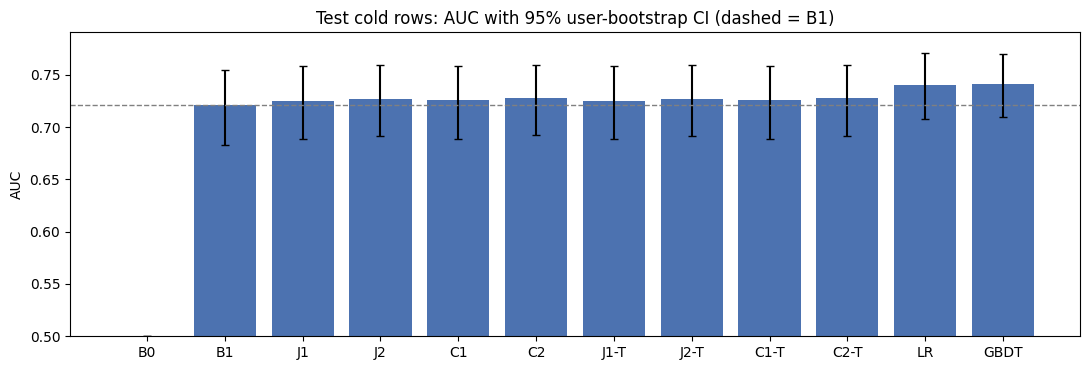

2 x 2 x 2 (test AUC)


,tags,ingredients
"Jaccard, λ = 0",0.7254,0.7273
"Jaccard, λ > 0",0.7254,0.7274
"Cosine, λ = 0",0.7257,0.7275
"Cosine, λ > 0",0.7256,0.7275


In [23]:
order = ["B0", "B1", "J1", "J2", "C1", "C2", "J1-T", "J2-T", "C1-T", "C2-T", "LR", "GBDT"]
t = res_te.loc[order]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(t.index, t.AUC, yerr=[t.AUC - t.AUC_lo, t.AUC_hi - t.AUC], color="#4C72B0", capsize=3)
ax.axhline(t.loc["B1", "AUC"], color="gray", ls="--", lw=1)
ax.set(ylim=(0.5, max(t.AUC_hi) + 0.02), ylabel="AUC", title="Test cold rows: AUC with 95% user-bootstrap CI (dashed = B1)")
plt.tight_layout(); plt.savefig(RESULTS / "test_auc.png", dpi=150); plt.show()
print("2 x 2 x 2 (test AUC)")
grid_table(res_te)

### 4.3 排名：Hit@10／NDCG@10（test）

每個 list = 一筆 5 分的 cold test 評論 + 99 道這個 user 沒評過、當天已發布、train + validation 中沒有評論的新食譜。
B0、B1 對同一個 user 的所有食譜給相同分數，等於隨機（Hit@10 = 0.10）。配對差距以 J1 為基準。

In [24]:
reviewed = pd.concat([train, val, test]).groupby("user_id").recipe_id.agg(set).to_dict()

def ranking_lists(history, rows):
    # one list per sampled 5-star cold review: the positive + N_NEG new recipes the user never reviewed
    positives = rows[(rows.cold == 1) & (rows.y_eq5 == 1)]
    cands = sample_candidates(positives, history, recipes, reviewed, n_lists=N_RANK_LISTS, n_neg=N_NEG)
    snap = make_snapshot("candidates", history, cands, rsets, H=H, max_df=MAX_DF)
    assert snap.n == len(cands)
    return cands, snap

def ranking_table(cands, scores, base):
    per = {k: ranking_metrics(cands, s) for k, s in scores.items()}
    users = next(iter(per.values())).user_id.values
    hit = mean_ci({k: v["Hit@10"].values for k, v in per.items()}, users, n_boot=N_BOOT, base=base)
    ndcg = mean_ci({k: v["NDCG@10"].values for k, v in per.items()}, users, n_boot=N_BOOT, base=base)
    return hit, ndcg

t0 = time.time()
history_te = pd.concat([train, val], ignore_index=True)
cands_te, snap_ct = ranking_lists(history_te, test)
prior_ct = user_prior(snap_ct, LABEL, BETA)
X_ct = build_features(snap_ct, recipes, LABEL, BETA, WA, LAM_USER)
scores_ct = {"B1": prior_ct, **wa_predictions(snap_ct, prior_ct),
             "LR": predict(lr_fin, X_ct), "GBDT": gb_fin.predict_proba(X_ct.values)[:, 1]}
hit_te, ndcg_te = ranking_table(cands_te, scores_ct, base="J1")
hit_te.to_csv(RESULTS / "test_ranking_hit10.csv"); ndcg_te.to_csv(RESULTS / "test_ranking_ndcg10.csv")
print(f"{cands_te.list_id.nunique():,} lists, {time.time() - t0:.0f}s")
pd.concat({"Hit@10": pretty(hit_te), "NDCG@10": pretty(ndcg_te)}, axis=1)

1,000 lists, 9s


Hit@10                                                           NDCG@10                                         
                          mean                           Δ p_not_better                     mean                           Δ p_not_better
model                                                                                                                                    
B1     0.1000 [0.1000, 0.1000]  -0.0390 [-0.0631, -0.0171]        1.000  0.0454 [0.0454, 0.0454]  -0.0205 [-0.0325, -0.0097]        1.000
J1     0.1390 [0.1171, 0.1631]           +nan [+nan, +nan]          nan  0.0660 [0.0551, 0.0779]           +nan [+nan, +nan]          nan
J1-T   0.1410 [0.1193, 0.1646]  +0.0020 [+0.0000, +0.0049]        0.147  0.0668 [0.0558, 0.0788]  +0.0008 [-0.0001, +0.0019]        0.042
J2     0.1180 [0.0954, 0.1442]  -0.0210 [-0.0516, +0.0104]        0.911  0.0610 [0.0485, 0.0752]  -0.0050 [-0.0212, +0.0111]        0.727
J2-T   0.1180 [0.0942, 0.1430]  -0.0210 [-0.0517, +0.0096]        0.910  0.0600 [0.0476, 0.0744]  -0.0060 [-0.0220, +0.0099]        0.766
C1     0.1360 [0.1148, 0.1601]  -0.0030 [-0.0133, +0.0071]        0.777  0.0619 [0.0516, 0.0729]  -0.0041 [-0.0084, +0.0000]        0.974
C1-T   0.1400 [0.1189, 0.1636]  +0.0010 [-0.0084, +0.0100]        0.481  0.0633 [0.0529, 0.0743]  -0.0027 [-0.0066, +0.0012]        0.924
C2     0.1220 [0.1004, 0.1468]  -0.0170 [-0.0487, +0.0132]        0.868  0.0615 [0.0492, 0.0757]  -0.0044 [-0.0206, +0.0115]        0.699
C2-T   0.1240 [0.1006, 0.1498]  -0.0150 [-0.0449, +0.0161]        0.830  0.0622 [0.0497, 0.0770]  -0.0038 [-0.0199, +0.0122]        0.668
LR     0.2050 [0.1708, 0.2396]  +0.0660 [+0.0257, +0.1035]        0.002  0.0942 [0.0772, 0.1122]  +0.0282 [+0.0091, +0.0470]        0.004
GBDT   0.2200 [0.1715, 0.2690]  +0.0810 [+0.0266, +0.1351]        0.000  0.1113 [0.0881, 0.1367]  +0.0454 [+0.0171, +0.0722]        0.000

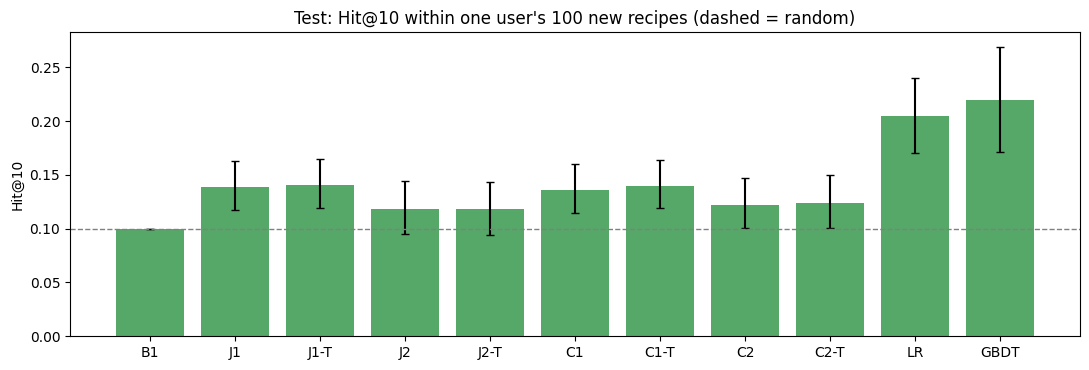

In [25]:
t = hit_te.loc[list(scores_ct)]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(t.index, t["mean"], yerr=[t["mean"] - t.lo, t.hi - t["mean"]], color="#55A868", capsize=3)
ax.axhline(10 / (N_NEG + 1), color="gray", ls="--", lw=1)
ax.set(ylabel="Hit@10", title="Test: Hit@10 within one user's 100 new recipes (dashed = random)")
plt.tight_layout(); plt.savefig(RESULTS / "test_hit10.png", dpi=150); plt.show()

### 4.4 依歷史長度、calibration、係數

,3-5 (n=122),6-20 (n=360),"21+ (n=3,617)"
B1,0.6981,0.7926,0.7160
C2,0.7085,0.7922,0.7221
LR,0.6392,0.7942,0.7396
GBDT,0.7146,0.7994,0.7354


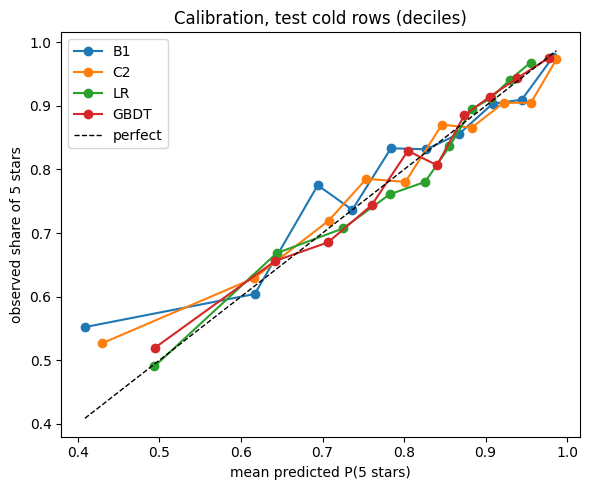

In [26]:
def by_history(snap, y, preds, mask, models):
    # AUC by the length of the user's history (rows within `mask`)
    n_hist = snap.targets.u.map(snap.history.u.value_counts()).values
    bins = {"3-5": n_hist <= 5, "6-20": (n_hist > 5) & (n_hist <= 20), "21+": n_hist > 20}
    return pd.DataFrame({f"{b} (n={(mask & m).sum():,})": {k: auc(y[mask & m], preds[k][mask & m]) for k in models}
                         for b, m in bins.items()})

def calibration_plot(ax, y, preds, models, title):
    lo, hi = 1, 0
    for k in models:
        p = preds[k]
        g = pd.DataFrame({"p": p, "y": y}).groupby(pd.qcut(p, 10, duplicates="drop"), observed=True).mean()
        ax.plot(g.p, g.y, marker="o", label=k)
        lo, hi = min(lo, g.p.min(), g.y.min()), max(hi, g.p.max(), g.y.max())
    ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="perfect")
    ax.set(title=title, xlabel="mean predicted P(5 stars)", ylabel="observed share of 5 stars"); ax.legend()

best_wa = res_te.loc[list(WA)].AUC.idxmax()
diag_models = ["B1", best_wa, "LR", "GBDT"]
hist_te = by_history(snap_test, y_te, preds_te, cold_te, diag_models)
hist_te.to_csv(RESULTS / "test_by_history.csv")
display(hist_te)
fig, ax = plt.subplots(figsize=(6, 5))
calibration_plot(ax, y_te[cold_te], {k: preds_te[k][cold_te] for k in diag_models}, diag_models,
                 "Calibration, test cold rows (deciles)")
plt.tight_layout(); plt.savefig(RESULTS / "test_calibration.png", dpi=150); plt.show()

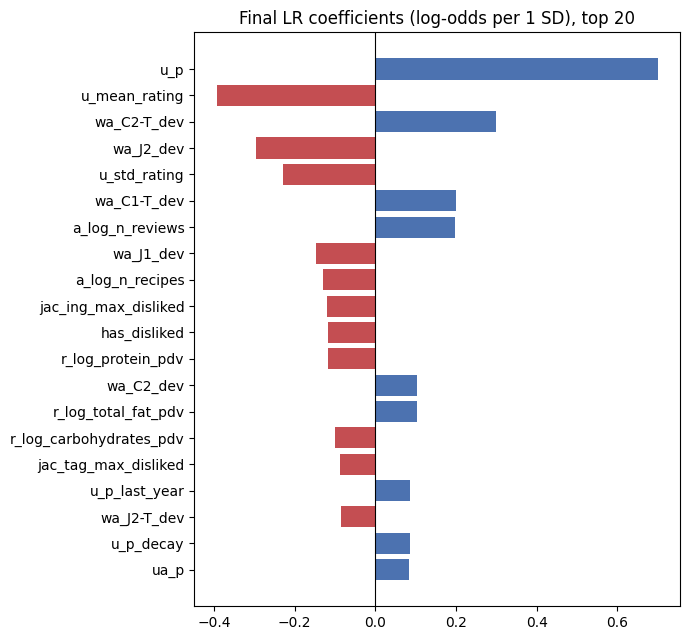

In [27]:
coef = lr_coefficients(lr_fin, X_fin.columns)
coef.to_csv(RESULTS / "lr_coefficients.csv", index=False)
top = coef.head(20).iloc[::-1]
plt.figure(figsize=(7, 6.5))
plt.barh(top.feature, top.coef, color=np.where(top.coef > 0, "#4C72B0", "#C44E52"))
plt.title("Final LR coefficients (log-odds per 1 SD), top 20"); plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.savefig(RESULTS / "lr_coefficients.png", dpi=150); plt.show()

In [28]:
summary = pd.DataFrame({"validation AUC": res_val.AUC, "test AUC": res_te.AUC.reindex(res_val.index),
                        "test ΔAUC vs B1": cmp_te["ΔAUC"].reindex(res_val.index),
                        "p (not better than B1)": cmp_te["p_not_better_AUC"].reindex(res_val.index),
                        "test Hit@10": hit_te["mean"].reindex(res_val.index)})
summary.to_csv(RESULTS / "summary.csv")
summary

,validation AUC,test AUC,test ΔAUC vs B1,p (not better than B1),test Hit@10
model,,,,,
B0,0.5000,0.5000,NaN,NaN,NaN
B1,0.7252,0.7209,NaN,NaN,0.1000
J1,0.7305,0.7254,0.0045,0.1090,0.1390
J1-T,0.7305,0.7254,0.0044,0.1050,0.1410
J2,0.7297,0.7273,0.0063,0.0290,0.1180
J2-T,0.7296,0.7274,0.0064,0.0250,0.1180
C1,0.7302,0.7257,0.0047,0.0760,0.1360
C1-T,0.7302,0.7256,0.0047,0.0740,0.1400
C2,0.7297,0.7275,0.0066,0.0100,0.1220


## 5. 相關文獻

- **資料集**：Majumder et al. (2019), *Generating Personalized Recipes from Historical User Preferences*, EMNLP。
- **Item-to-item 相似度推薦**：Linden, Smith & York (2003), Amazon.com recommendations。課堂的 Jaccard 加權評分預測即屬此類；本作業把 user 集合換成食譜內容集合，以處理新食譜。
- **Latent factor 與 cold-start**：Koren, Bell & Volinsky (2009)；沒有評論的 item 學不到 γ_i、β_i。
- **時間動態**：Koren (2009), *Collaborative Filtering with Temporal Dynamics*。
- **User 等於其 item 的平均**：Kabbur et al. (2013), FISM，與相似度加權平均的想法相近。

## 6. 結論

（依 4.1–4.4 的結果填寫：B1 與相似度模型的 AUC 差距與配對檢定、Hit@10 上 Jaccard vs Cosine 與 tags vs ingredients、
時間衰減是否有幫助、pseudo-cold 訓練列的效果、LR／GBDT 的增益、calibration 與係數解讀。）